# Interstellar Objects in the LSST Era: Which Will Rubin See?

*Matthew Payne*

In October 2017, Pan-STARRS1 found an object moving too fast to be bound to the Sun: 1I/ʻOumuamua, the first known visitor from another planetary system (Meech et al. 2017). The interstellar comet 2I/Borisov followed in 2019 (Guzik et al. 2020), and 3I/ATLAS in July 2025 (Seligman et al. 2025). The Vera C. Rubin Observatory, whose Legacy Survey of Space and Time (LSST) has begun, observed 3I/ATLAS within weeks of its discovery (Chandler et al. 2026).

How many more should Rubin find, where on the sky will they be, and could a spacecraft reach any of them? This notebook reproduces, step by step, the Monte Carlo of

> D. J. Hoover, D. Z. Seligman & M. J. Payne (2022), *The Population of Interstellar Objects Detectable with the LSST and Accessible for In Situ Rendezvous with Various Mission Designs*, PSJ **3**, 71. [ADS](https://ui.adsabs.harvard.edu/abs/2022PSJ.....3...71H/abstract) · [arXiv:2109.10406](https://arxiv.org/abs/2109.10406)

which we refer to as HSP22. They draw a million ʻOumuamua-like objects from the motions of nearby stars, follow each through the inner Solar System, and ask whether the LSST could see it, and with what change of velocity ($\Delta v$) a spacecraft leaving Earth could meet it.

We will:

1. Build the velocity distribution of interstellar objects from the kinematics of nearby stars, and map where on the sky they come from.
2. Launch a million objects into the inner Solar System as HSP22 do, and follow each one on its exact hyperbolic orbit.
3. Compute each object's brightness as seen from Earth, and decide on which nights Rubin could see it.
4. Measure the detectable fraction, and compare with HSP22.
5. Describe the detectable population: where it appears on the sky, its orbits, its closest approaches and the warning time before them.
6. Estimate the $\Delta v$ needed to reach each object, and turn fractions into yearly rates.
7. Place 1I, 2I and 3I in this picture.
8. Test how the numbers depend on the modelling choices.

Figure and table numbers in the text refer to HSP22.

**Requirements:** `numpy`, `matplotlib` and `rebound` (used once, to check the orbits).

**Run time:** about 5 minutes on a 12-core laptop, most of it in Section 8. Set `QUICK = True` for a 200,000-object version that takes about a minute.

In [1]:
import os
import time
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np

import iso   # helper module in this folder: kinematics, orbits, brightness and visibility

QUICK = False                         # True: 200,000 objects instead of 1,000,000
N_OBJ = 200_000 if QUICK else 1_000_000
N_CHUNK = 50                          # work units for the process pool
NPROC = os.cpu_count()
print(f"{N_OBJ:,} objects on {NPROC} processes")

def sky_x(ra):
    # Mollweide x for right ascension in degrees: RA increases to the left, 12h at the centre
    return np.radians((180.0 - np.asarray(ra) + 180.0) % 360.0 - 180.0)

def sky_axes(fig, pos, title):
    ax = fig.add_subplot(pos, projection="mollweide")
    ax.set_xticks(np.radians([150, 120, 90, 60, 30, 0, -30, -60, -90, -120, -150]))
    ax.set_xticklabels(["2h", "4h", "6h", "8h", "10h", "12h", "14h", "16h", "18h", "20h", "22h"], fontsize=7)
    ax.tick_params(axis="y", labelsize=7)
    ax.grid(alpha=0.3)
    ax.set_title(title, fontsize=10, pad=12)
    return ax

def sky_line(ax, ra, dec, **kw):
    # Draw a curve on the sky without the wrap-around jump at RA = 0h
    x = sky_x(ra)
    jump = np.flatnonzero(np.abs(np.diff(x)) > np.pi)
    for seg_x, seg_d in zip(np.split(x, jump + 1), np.split(np.radians(dec), jump + 1)):
        ax.plot(seg_x, seg_d, **kw)
        kw.pop("label", None)

def great_circle(matrix):
    # Equatorial RA, Dec of the equator of a frame (for example the ecliptic or Galactic plane)
    lon = np.radians(np.linspace(0, 360, 721))
    u = np.stack([np.cos(lon), np.sin(lon), np.zeros_like(lon)], -1) @ matrix.T
    ra, dec = iso.unit_to_radec(u)
    order = np.argsort(ra)
    return ra[order], dec[order]

ECLIPTIC = great_circle(iso.EQ_TO_ECL.T)
GALACTIC = great_circle(iso.GAL_TO_EQ)
APEX = iso.solar_apex()
KNOWN = {name: iso.asymptote(**el) for name, el in iso.KNOWN.items()}
KNOWN_STYLE = {"1I/ʻOumuamua": ("*", "red"), "2I/Borisov": ("D", "orange"), "3I/ATLAS": ("P", "magenta")}

def sky_context(ax, lsst=False):
    sky_line(ax, *ECLIPTIC, color="k", lw=1, label="ecliptic")
    sky_line(ax, *GALACTIC, color="0.5", lw=1, ls=":", label="Galactic plane")
    if lsst:
        ax.axhline(np.radians(12), color="red", lw=1, ls="--", label="Dec = +12°")
    ax.plot(sky_x(APEX[0]), np.radians(APEX[1]), "wo", mec="k", ms=7, label="solar apex")
    for name, (v, ra, dec) in KNOWN.items():
        mk, col = KNOWN_STYLE[name]
        ax.plot(sky_x(ra), np.radians(dec), mk, color=col, mec="k", ms=9, label=f"{name} radiant")

def sky_hist(ax, ra, dec, bins=(72, 36), cmap="viridis", south_scale=False):
    # Density per unit solid angle of points on the sky
    H, ra_e, dec_e = np.histogram2d(ra, dec, bins=bins, range=[[0, 360], [-90, 90]])
    solid = np.diff(np.sin(np.radians(dec_e)))[None, :] * np.diff(np.radians(ra_e))[:, None]
    dens = (H / solid).T
    X, Y = np.meshgrid(sky_x(0.5 * (ra_e[1:] + ra_e[:-1])), np.radians(0.5 * (dec_e[1:] + dec_e[:-1])))
    order = np.argsort(X[0])
    # Optionally scale the colours to the cells south of the equator, so that a band of
    # first detections at the survey's northern edge does not swamp the map
    vmax = np.percentile(dens[Y[:, 0] < 0], 99.5) if south_scale else None
    return ax.pcolormesh(X[:, order], Y[:, order], dens[:, order], shading="auto", cmap=cmap, vmax=vmax, rasterized=True)

1,000,000 objects on 12 processes


## 1. Where do interstellar objects come from?

HSP22 assume that interstellar objects have been stirred, over the Galaxy's history, into the same velocity distribution as the stars around the Sun. Relative to the Local Standard of Rest (LSR), the average motion of stars near the Sun, they adopt a Schwarzschild distribution: a three-dimensional Gaussian with dispersions $\sigma_R$, $\sigma_\phi$, $\sigma_z$, whose long axis is turned from the direction of the Galactic Centre by the *vertex deviation* $v_d$. Their Table 1 gives values for three stellar populations, from Binney & Merrifield (1998); the G-dwarf values are their default.

| Population | $\sigma_R$ (km/s) | $\sigma_\phi$ (km/s) | $\sigma_z$ (km/s) | $v_d$ |
|---|---|---|---|---|
| M dwarfs | 31 | 23 | 16 | 7° |
| G dwarfs | 26 | 18 | 15 | 12° |
| O/B stars | 12 | 11 | 9 | 36° |

The Sun itself moves relative to the LSR, towards the *solar apex*. An object at rest in the LSR therefore seems, from the Sun, to come from the apex. HSP22 do not say which solar motion they used; we adopt $(U, V, W)_\odot = (11.1, 12.24, 7.25)$ km/s from Schönrich, Binney & Dehnen (2010), and in Section 8 try the older value of Dehnen & Binney (1998).

The Sun's gravity also bends the paths of slow objects towards it, so slow objects are over-represented among those passing close by. HSP22 approximate this *gravitational focusing* by weighting each velocity with

$$\xi \approx 1 + \left(\frac{42\ \mathrm{km/s}}{v_\infty + \beta}\right)^2,$$

where $v_\infty$ is the speed relative to the Sun far away, 42 km/s is the escape speed from the Sun at 1 au, and $\beta = 2$ km/s avoids the infinity at $v_\infty = 0$.

The function `iso.radiant_map` integrates this weighted distribution over speed, for every direction on the sky, to give the probability that an object arrives *from* that direction (the radiant). This reproduces HSP22's Figure 1.

Solar apex (Schönrich et al. 2010): RA = 267.1°, Dec = +23.1°
1I/ʻOumuamua   radiant RA =  279.6°, Dec = +33.9°,  v_inf =  26.4 km/s
2I/Borisov     radiant RA =   32.8°, Dec = +59.5°,  v_inf =  32.3 km/s
3I/ATLAS       radiant RA =  295.0°, Dec = -19.1°,  v_inf =  58.0 km/s


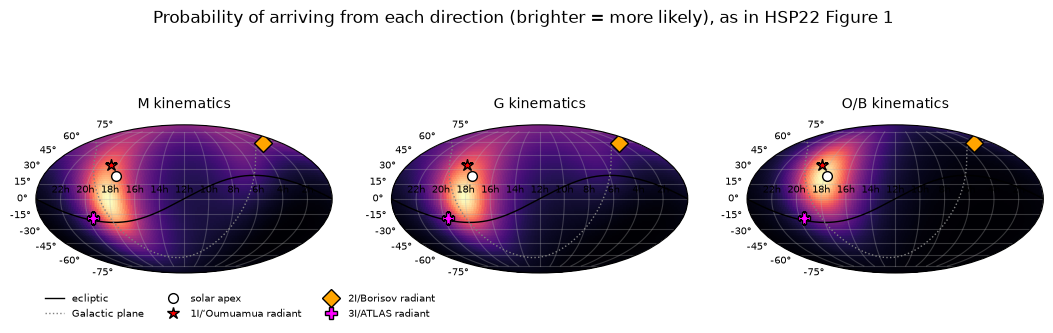

In [2]:
print(f"Solar apex (Schönrich et al. 2010): RA = {APEX[0]:.1f}°, Dec = {APEX[1]:+.1f}°")
for name, (v, ra, dec) in KNOWN.items():
    print(f"{name:14s} radiant RA = {ra:6.1f}°, Dec = {dec:+5.1f}°,  v_inf = {v:5.1f} km/s")

fig = plt.figure(figsize=(13, 3.6))
for k, pop in enumerate(["M", "G", "O/B"]):
    ra_e, dec_e, dens = iso.radiant_map(pop)
    ax = sky_axes(fig, 131 + k, f"{pop} kinematics")
    X, Y = np.meshgrid(sky_x(0.5 * (ra_e[1:] + ra_e[:-1])), np.radians(0.5 * (dec_e[1:] + dec_e[:-1])))
    order = np.argsort(X[0])
    ax.pcolormesh(X[:, order], Y[:, order], dens[:, order], shading="auto", cmap="magma", rasterized=True)
    sky_context(ax)
fig.axes[0].legend(loc="upper left", bbox_to_anchor=(0.0, -0.08), ncol=3, fontsize=7, frameon=False)
fig.suptitle("Probability of arriving from each direction (brighter = more likely), as in HSP22 Figure 1", y=1.02)
plt.show()

In all three populations the radiants cluster around the solar apex, in Hercules, and spread more widely for the hotter (older) M-dwarf kinematics. ʻOumuamua arrived from close to the apex, as Mamajek (2017) pointed out. Borisov and 3I/ATLAS came from far away from it, and both were faster: 32 and 58 km/s, against ʻOumuamua's 26 km/s. As HSP22 note, faster objects are likely to be older, with more nearly isotropic directions.

## 2. Launching a million objects

HSP22 start every object on a sphere of radius 5 au around the Sun, heading inwards (their Figure 2):

1. Draw a velocity at infinity, $\vec v_\infty$, from the weighted distribution of Section 1.
2. Draw an offset $b$ perpendicular to $\vec v_\infty$ from $p(b) \propto b^2$ between 0 and 5 au, and an angle $\psi$ uniformly in $(0, 2\pi)$ for its direction around $\vec v_\infty$.
3. Place the object at $\vec R = -\sqrt{R^2 - b^2}\,\hat v_\infty + \vec b$ with $R = 5$ au, so that it lies exactly on the sphere.
4. Raise its speed to $\sqrt{v_\infty^2 + v_\mathrm{esc}^2}$, where $v_\mathrm{esc} = 18.8$ km/s is the escape speed at 5 au, keeping the direction of $\vec v_\infty$.

We draw the velocities by rejection sampling, exactly from the continuous distribution, within HSP22's box of $\pm100$ km/s in each component. HSP22 tabulate the distribution on a $100^3$ grid and draw from it with a spline and differential evolution; with a million objects the two methods should agree. Each object also gets a start date, uniformly through 2021, which sets where the Earth is.

HSP22 then integrate the Sun, the Earth and each object for 3 years with REBOUND. The Earth's pull on these objects is negligible, so each object's path is a Keplerian hyperbola about the Sun, which we compute exactly (`iso.positions` solves Kepler's equation, $e\sinh F - F = M$). First, a check against a direct REBOUND integration:

In [3]:
import rebound

ic = iso.initial_conditions(200, seed=1)
el = iso.elements(ic["r0"], ic["v0"])
t_check = np.array([0.0, 200.0, 600.0, iso.T_SPAN])
kepler = iso.positions(el, t_check)

sim = rebound.Simulation()
sim.G = iso.GM_SUN                    # au, days, solar masses
sim.add(m=1.0)
for r, v in zip(ic["r0"], ic["v0"]):
    sim.add(x=r[0], y=r[1], z=r[2], vx=v[0], vy=v[1], vz=v[2])
sim.N_active = 1                      # the objects are test particles
sim.integrator = "ias15"
worst = 0.0
for k, t in enumerate(t_check):
    sim.integrate(t)
    nbody = np.array([sim.particles[j + 1].xyz for j in range(200)]) - np.array(sim.particles[0].xyz)
    worst = max(worst, np.abs(nbody - kepler[:, k]).max())
print(f"Largest difference between Kepler's equation and REBOUND over 3 years: {worst:.1e} au")

Largest difference between Kepler's equation and REBOUND over 3 years: 3.7e-12 au


The two agree to rounding error, so from here on we use the exact solution, which lets us follow every object night by night.

Each object is sampled once per night for 3 years. Objects whose perihelion lies beyond 2.5 au are not followed: even at their closest they are at least 2.5 au from the Sun and 1.5 au from the Earth, too far for an ʻOumuamua-sized body to reach magnitude 24.

## 3. Brightness, and when Rubin can look

HSP22 compute the apparent magnitude of an object of absolute magnitude $H$ as

$$m = H + 2.5\log_{10}\left(\frac{d_{BS}^2\, d_{BO}^2}{p(\theta)\, d_{OS}^4}\right),$$

where $d_{BS}$, $d_{BO}$ and $d_{OS}$ are the body–Sun, body–observer and observer–Sun distances, $\theta$ is the phase angle at the body, and

$$p(\theta) = \frac{2}{3}\left[\left(1-\frac{\theta}{\pi}\right)\cos\theta + \frac{1}{\pi}\sin\theta\right]$$

is the phase integral of a Lambert sphere. Every object is given ʻOumuamua's $H = 22.4$, and no cometary activity. Their Figure 5 shows why the brightest objects appear near the ecliptic: at a fixed distance from the Earth, an object is brightest at small phase angle, opposite the Sun.

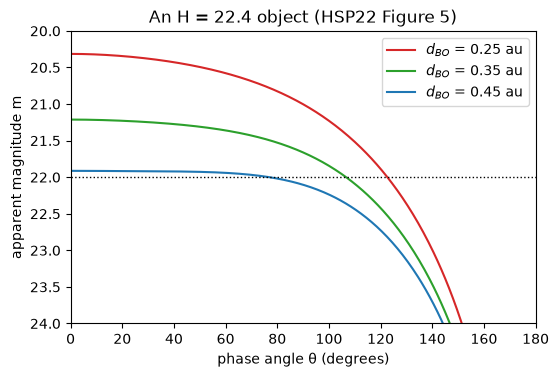

In [4]:
theta = np.radians(np.linspace(0, 180, 361))
fig, ax = plt.subplots(figsize=(6, 3.8))
for d_bo, col in [(0.25, "C3"), (0.35, "C2"), (0.45, "C0")]:
    # Earth at 1 au; the body's distance from the Sun follows from the triangle
    d_bs = d_bo * np.cos(theta) + np.sqrt(1 - (d_bo * np.sin(theta)) ** 2)
    ax.plot(np.degrees(theta), iso.apparent_magnitude(22.4, d_bs, d_bo, 1.0), color=col, label=f"$d_{{BO}}$ = {d_bo} au")
ax.axhline(22, color="k", ls=":", lw=1)
ax.set(xlim=(0, 180), ylim=(24, 20), xlabel="phase angle θ (degrees)", ylabel="apparent magnitude m",
       title="An H = 22.4 object (HSP22 Figure 5)")
ax.legend()
plt.show()

These curves match HSP22's Figure 5. They are flatter than one might expect: at 0.45 au from the Earth the object stays brighter than $m = 22$ out to a phase angle of almost 80°, because a larger phase angle also brings it closer to the Sun.

HSP22 count an object as *detectable* by the LSST if, at some point along its path:

1. its apparent magnitude is between 16 (brighter objects saturate in Rubin's 30-second exposures) and 24 (the faintest Rubin can see);
2. it is more than 30° above the horizon at Rubin, and its declination is below +12°, the northern edge of the Wide-Fast-Deep survey over most right ascensions;
3. the Sun is more than 18° below the horizon (astronomical twilight).

Criteria 2 and 3 depend on the time of night. We apply them to each night as a whole: on a given night the object is *observable* if, at some moment, it is above 30° while the Sun is below $-18°$. In local sidereal time the object is up on an arc centred on its right ascension, and the sky is dark on an arc centred on the anti-Sun, so the test is whether two arcs overlap (`iso.observable_tonight`). This treats the LSST as covering the whole sky south of +12° every night, with no weather, Moon or cadence, as HSP22 do; their simulation sampled each trajectory at 100 instants instead, and we return to the difference in Section 4.

## 4. A million objects: how many could Rubin see?

`iso.run` splits the population into chunks and follows them on a process pool. For each object that ever comes within reach it records the first observable night with $16 < m \le 24$ (for each of HSP22's four absolute magnitudes), its closest approach to the Earth, and where it was on the sky.

In [5]:
t0 = time.time()
with Pool(NPROC) as pool:
    allq, det = iso.run(N_OBJ, N_CHUNK, pool)
N_EACH = N_OBJ // N_CHUNK
print(f"{N_OBJ:,} objects in {time.time() - t0:.0f} s; {np.mean(allq['q'] < iso.Q_CUT):.1%} pass within {iso.Q_CUT} au of the Sun")

reach24 = allq["m_min"] <= 24
detected = det["det_22.4"] >= 0
print(f"Reach m <= 24 at some point:  {reach24.mean():.3%}   (HSP22: 6.956%)")
print(f"Detectable by the LSST:       {detected.sum() / N_OBJ:.3%}   (HSP22: 2.828%)")

1,000,000 objects in 67 s; 22.4% pass within 2.5 au of the Sun
Reach m <= 24 at some point:  6.274%   (HSP22: 6.956%)
Detectable by the LSST:       3.848%   (HSP22: 2.828%)


Here is one detectable object: its path through the inner Solar System, and its brightness night by night.

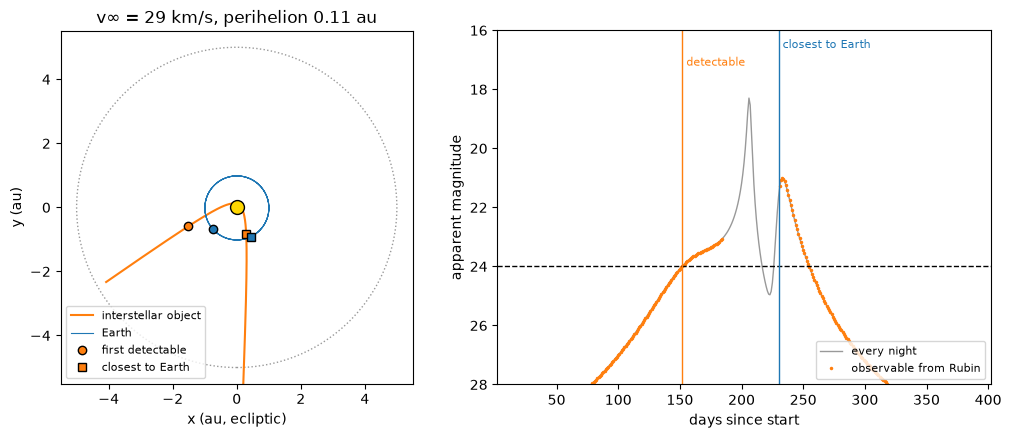

First detectable on day 152; closest to Earth (0.22 au) 78 days later; Δv ≈ 4.8 km/s (Section 6)


In [6]:
# One detectable object, followed night by night
v_det_all = allq["v_inf"][det["id"]]
pick = np.flatnonzero(detected & (v_det_all > 15) & (v_det_all < 35) & (det["d_min"] > 0.2) & (det["d_min"] < 0.5) & (det["t_ca"] > det["det_22.4"] + 40))[0]
tr = iso.track(det["id"][pick], N_EACH)
day_det = det["det_22.4"][pick]
day_ca = det["t_ca"][pick]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
a1.plot(tr["r"][:, 0], tr["r"][:, 1], color="C1", label="interstellar object")
a1.plot(tr["earth"][:, 0], tr["earth"][:, 1], color="C0", lw=0.8, label="Earth")
a1.plot(0, 0, "o", color="gold", mec="k", ms=10)
for d, mk, lab in [(day_det, "o", "first detectable"), (int(round(day_ca)), "s", "closest to Earth")]:
    a1.plot(*tr["r"][d, :2], mk, color="C1", mec="k", label=lab)
    a1.plot(*tr["earth"][d, :2], mk, color="C0", mec="k")
a1.set(xlim=(-5.5, 5.5), ylim=(-5.5, 5.5), aspect="equal", xlabel="x (au, ecliptic)", ylabel="y (au)",
       title=f"v∞ = {tr['v_inf']:.0f} km/s, perihelion {tr['q']:.2f} au")
a1.add_patch(plt.Circle((0, 0), 5, fill=False, ls=":", color="0.6"))
a1.legend(fontsize=8, loc="lower left")

d = tr["days"]
a2.plot(d, tr["m"], color="0.6", lw=1, label="every night")
a2.plot(d[tr["obs"]], tr["m"][tr["obs"]], ".", color="C1", ms=3, label="observable from Rubin")
a2.axhline(24, color="k", ls="--", lw=1)
a2.axvline(day_det, color="C1", lw=1)
a2.axvline(day_ca, color="C0", lw=1)
a2.text(day_det, 17.2, " detectable", color="C1", fontsize=8)
a2.text(day_ca, 16.6, " closest to Earth", color="C0", fontsize=8)
lo = max(0, day_det - 150)
a2.set(xlim=(lo, lo + 400), ylim=(28, 16), xlabel="days since start", ylabel="apparent magnitude")
a2.legend(fontsize=8, loc="lower right")
plt.show()
wait = day_ca - day_det
print(f"First detectable on day {day_det}; closest to Earth ({det['d_min'][pick]:.2f} au) {wait:.0f} days later; "
      f"Δv ≈ {det['d_min'][pick] / wait * iso.AU_KM / iso.DAY_S:.1f} km/s (Section 6)")

Our fraction of objects that reach $m \le 24$ is close to HSP22's: slightly lower, which could come from the solar motion, the way velocities are drawn, or how finely the brightest point is resolved (Section 8 explores the first). The detectable fraction is more sensitive to how criteria 2 and 3 are applied. HSP22 evaluated their trajectories at 100 instants over the 3 years, roughly every 11 days; whether a given instant fell in the night at Rubin then depends on its time of day. To see how much that matters, `iso.detect_at_instants` judges the same objects in both ways at 100 instants: by the altitudes at each instant, and by our whole-night test.

In [7]:
with Pool(NPROC) as pool:
    parts = pool.map(iso.detect_at_instants, [(N_EACH, 2022 + k, "G", iso.DEFAULT_SOLAR, True, 2) for k in range(N_CHUNK)])
instant = np.concatenate([p[0] for p in parts])
night = np.concatenate([p[1] for p in parts])
print(f"Reach 16 < m <= 24 at one of the 100 instants: {instant.size / N_OBJ:.3%}")
print(f"  ... and observable at that instant:          {instant.sum() / N_OBJ:.3%}")
print(f"  ... and observable on that night:            {night.sum() / N_OBJ:.3%}")
print(f"Nightly sampling, whole-night test (above):    {detected.sum() / N_OBJ:.3%}")
print("HSP22:                                        2.828%")

Reach 16 < m <= 24 at one of the 100 instants: 6.236%
  ... and observable at that instant:          1.148%
  ... and observable on that night:            3.620%
Nightly sampling, whole-night test (above):    3.848%
HSP22:                                        2.828%


Judged at single instants, about two-thirds of the objects that are observable on some night are missed, because each sampled instant has only a modest chance of falling in darkness with the object high in the sky. HSP22's 2.8% lies between the instantaneous and whole-night results; they also mention a cubic interpolation of the trajectories, which would sit between the two. The physically meaningful question for a survey that observes every night is the whole-night one, so we use it below, and keep in mind that the detectable fraction carries a factor of order 1.5 from this choice alone, before the much larger unknowns of the survey's real cadence, weather and detection efficiency.

## 5. The detectable population

### Where they come from, and where they are seen

HSP22's Figure 3 shows where detectable objects *enter* the 5 au sphere, and their Figure 4 where they are when first detectable, for limiting magnitudes of 24 (the LSST) and 22 (a shallower survey).

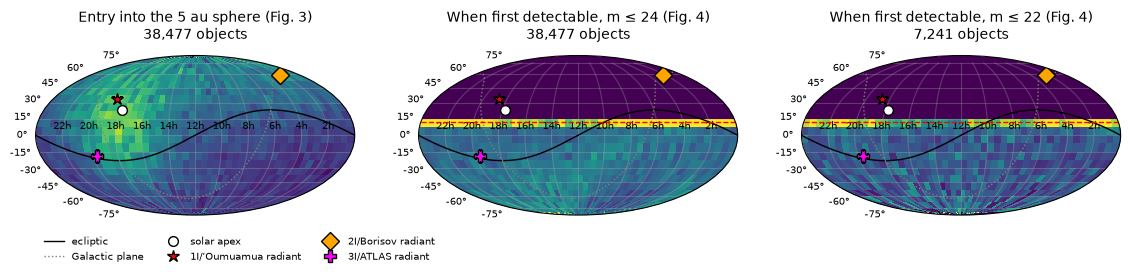

In [8]:
ids = det["id"]
fig = plt.figure(figsize=(14, 3.8))
panels = [
    (allq["ra_entry"][ids[detected]], allq["dec_entry"][ids[detected]], "Entry into the 5 au sphere (Fig. 3)"),
    (det["ra_det_24.0"][detected], det["dec_det_24.0"][detected], "When first detectable, m ≤ 24 (Fig. 4)"),
    (det["ra_det_22.0"][det["det_22.4"] >= 0], det["dec_det_22.0"][det["det_22.4"] >= 0], "When first detectable, m ≤ 22 (Fig. 4)"),
]
for k, (ra, dec) in enumerate([(p[0], p[1]) for p in panels]):
    ok = np.isfinite(ra)
    ax = sky_axes(fig, 131 + k, panels[k][2] + f"\n{ok.sum():,} objects")
    sky_hist(ax, ra[ok], dec[ok], bins=(48, 24), south_scale=k > 0)
    sky_context(ax, lsst=k > 0)
fig.axes[0].legend(loc="upper left", bbox_to_anchor=(0.0, -0.08), ncol=3, fontsize=7, frameon=False)
plt.show()

Detectable objects enter from near the apex, and also from the opposite direction (the anti-apex), as in HSP22's Figure 3. By the time they are bright enough to see they have moved along their paths, so the detection positions are much more spread out. The maps are cut off at +12°, the LSST's assumed northern limit, and show a bright band just south of it: objects that were already bright enough while further north become detectable on the first night they cross the limit. (HSP22's version of this map does not show the band; sampled at instants about 11 days apart, such objects would be caught at a random point after crossing.) In the second and third maps the colour scale is set by the cells south of the equator, so that the band does not hide the rest.

HSP22 find that the brightest objects, reaching $m \le 22$, cluster near the ecliptic, where the phase angle is small (Section 3). We can measure this directly, as the fraction of first detections within 20° of the ecliptic:

In [9]:
def ecliptic_latitude(ra, dec):
    ra, dec = np.radians(ra), np.radians(dec)
    return np.degrees(np.arcsin(np.sin(dec) * np.cos(iso.OBLIQUITY) - np.cos(dec) * np.sin(iso.OBLIQUITY) * np.sin(ra)))

for lim in (24.0, 22.0):
    ra, dec = det[f"ra_det_{lim}"], det[f"dec_det_{lim}"]
    ok = np.isfinite(ra)
    beta = ecliptic_latitude(ra[ok], dec[ok])
    print(f"First detectable at m <= {lim:.0f}: {np.mean(np.abs(beta) < 20):.0%} within 20° of the ecliptic, "
          f"{np.mean(dec[ok] > 8):.0%} within 4° of the +12° limit")
u = np.random.default_rng(1).normal(size=(1_000_000, 3))
u = u / np.linalg.norm(u, axis=1)[:, None]
u = u[u[:, 2] < np.sin(np.radians(12))]
print(f"Uniform sky south of +12°: {np.mean(np.abs(u @ iso.EQ_TO_ECL[2]) < np.sin(np.radians(20))):.0%} within 20° of the ecliptic")

First detectable at m <= 24: 45% within 20° of the ecliptic, 24% within 4° of the +12° limit
First detectable at m <= 22: 47% within 20° of the ecliptic, 24% within 4° of the +12° limit
Uniform sky south of +12°: 40% within 20° of the ecliptic


In our simulation the concentration towards the ecliptic is weak: only a little stronger for $m \le 22$ than for $m \le 24$, and not much above what a uniform sky would give. We have not found the cause of the difference from HSP22. One contributor may be that about a quarter of our first detections sit at the +12° edge rather than where the objects first became bright.


### Orbits and close approaches

Next, the orbital properties of the detectable objects, as in HSP22's Figures 6 and 8–15, together with the subset that a spacecraft could reach with $\Delta v < 20$ km/s (Section 6). The vertical lines mark 1I, 2I and 3I.

22% of detectable objects are first detectable only after their closest approach to Earth;
we count them as unreachable (an infinite Δv).


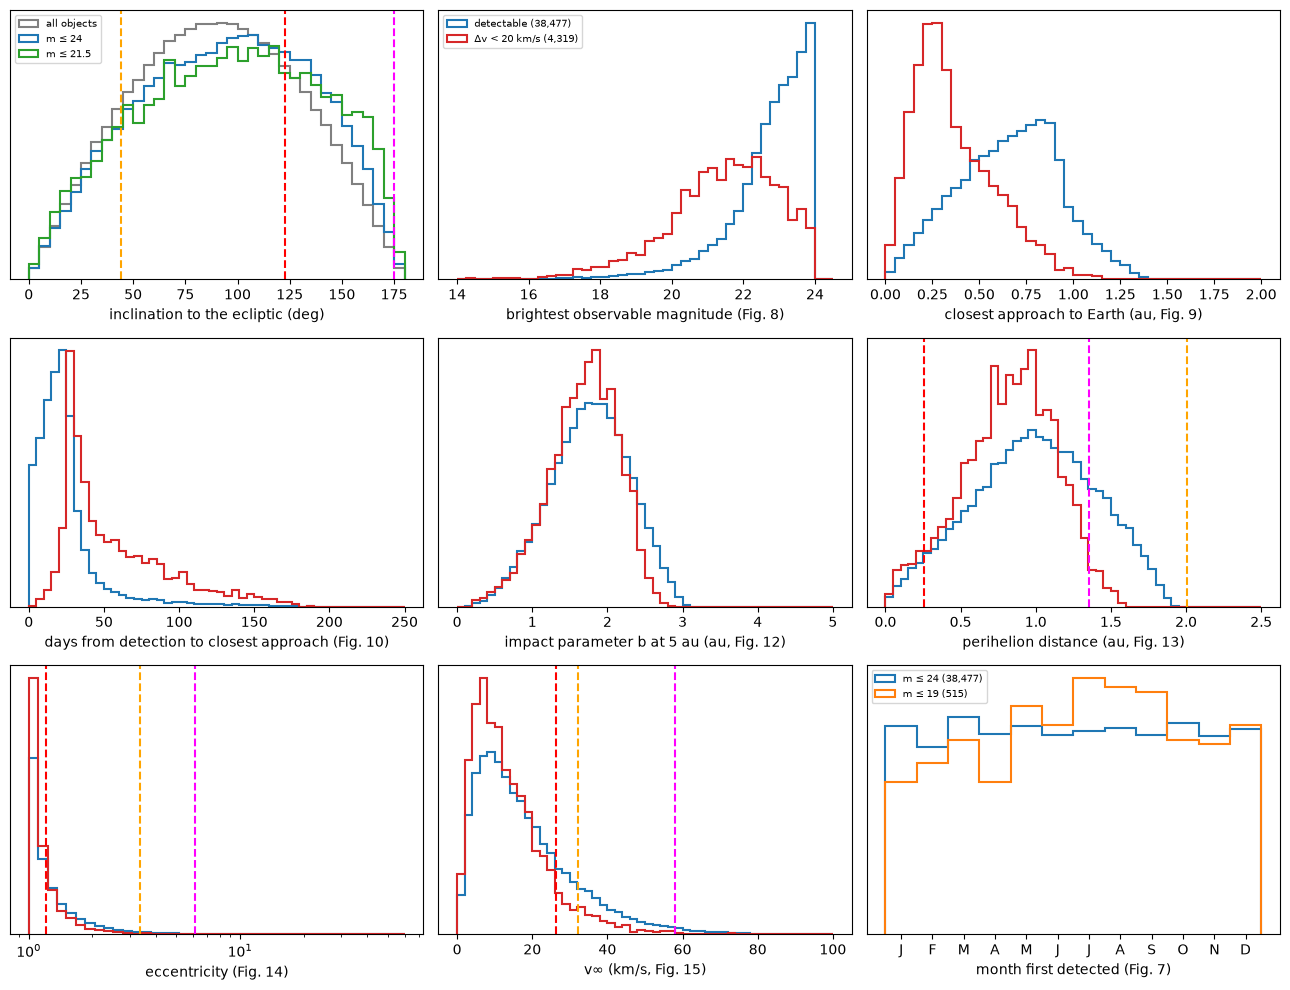

In [10]:
KMS = iso.AU_KM / iso.DAY_S                   # au/day -> km/s
det_day = det["det_22.4"].astype(float)
wait = det["t_ca"] - det_day                  # days from first detection to closest approach
dv = np.where(detected & (wait > 0), det["d_min"] / np.where(wait > 0, wait, 1) * KMS, np.inf)
reach = dv < 20
print(f"{np.mean(wait[detected] <= 0):.0%} of detectable objects are first detectable only after their closest approach to Earth;")
print("we count them as unreachable (an infinite Δv).")

known_el = {k: v for k, v in iso.KNOWN.items()}
def mark(ax, key):
    for name, el in known_el.items():
        mk, col = KNOWN_STYLE[name]
        val = {"v": KNOWN[name][0], "q": el["q"], "e": el["e"], "i": el["i"]}.get(key)
        if val is not None:
            ax.axvline(val, color=col, lw=1.5, ls="--")

fig, axs = plt.subplots(3, 3, figsize=(13, 10))
sets = [(detected, "detectable", "C0"), (reach, "Δv < 20 km/s", "C3")]

def hist(ax, values, bins, xlabel, key=None, log=False):
    for sel, lab, col in sets:
        ax.hist(values[sel], bins=bins, histtype="step", density=True, color=col, lw=1.5, label=f"{lab} ({sel.sum():,})")
    ax.set_xlabel(xlabel)
    if log:
        ax.set_xscale("log")
    if key:
        mark(ax, key)

a = axs.ravel()
# Inclination: all objects, and those reaching m <= 24 and m <= 21.5 (HSP22 Fig. 6)
for sel, lab, col in [(np.ones(N_OBJ, bool), "all objects", "0.5"), (allq["m_min"] <= 24, "m ≤ 24", "C0"), (allq["m_min"] <= 21.5, "m ≤ 21.5", "C2")]:
    a[0].hist(allq["inc"][sel], bins=np.linspace(0, 180, 37), histtype="step", density=True, color=col, lw=1.5, label=lab)
a[0].set_xlabel("inclination to the ecliptic (deg)"); mark(a[0], "i"); a[0].legend(fontsize=7)
hist(a[1], det["m_obs_min"], np.linspace(14, 24.5, 43), "brightest observable magnitude (Fig. 8)")
hist(a[2], det["d_min"], np.linspace(0, 2, 41), "closest approach to Earth (au, Fig. 9)")
hist(a[3], np.where(wait > 0, wait, np.nan), np.linspace(0, 250, 51), "days from detection to closest approach (Fig. 10)")
hist(a[4], allq["b"][ids], np.linspace(0, 5, 51), "impact parameter b at 5 au (au, Fig. 12)")
hist(a[5], allq["q"][ids], np.linspace(0, 2.5, 51), "perihelion distance (au, Fig. 13)", key="q")
hist(a[6], allq["e"][ids], np.logspace(0, np.log10(60), 41), "eccentricity (Fig. 14)", key="e", log=True)
hist(a[7], allq["v_inf"][ids], np.linspace(0, 100, 51), "v∞ (km/s, Fig. 15)", key="v")
a[1].legend(fontsize=7)
# Month of first detection (HSP22 Fig. 7), for m <= 24 and m <= 19
def month(jd):
    return ((np.datetime64("2000-01-01T12:00") + ((jd - iso.JD2000) * 86400).astype("timedelta64[s]")).astype("datetime64[M]").astype(int) % 12)
for col, key, lab in [("C0", "det_22.4", "m ≤ 24"), ("C1", "det_19", "m ≤ 19")]:
    ok = det[key] >= 0
    a[8].hist(month(det["jd0"][ok] + det[key][ok]), bins=np.arange(13) - 0.5, density=True, histtype="step", color=col, lw=1.5, label=f"{lab} ({ok.sum():,})")
a[8].set_xticks(range(12)); a[8].set_xticklabels("JFMAMJJASOND"); a[8].set_xlabel("month first detected (Fig. 7)"); a[8].legend(fontsize=7)
for ax in a:
    ax.set_yticks([])
fig.tight_layout()
plt.show()

These reproduce the patterns HSP22 describe:

* **Inclination:** most objects arrive on steeply inclined orbits, centred near 90°, because the solar apex lies far from the ecliptic. Brighter subsets look much the same.
* **Brightness:** very few detectable objects ever get brighter than $m \approx 19$.
* **Closest approach:** detectable objects pass within about 1.5 au of the Earth, and reachable ones within about 1 au.
* **Warning time:** most objects are first detectable a few weeks to a few months before their closest approach to Earth.
* **Impact parameter and perihelion:** although $b$ is drawn from a distribution rising as $b^2$, detection favours small $b$; the LSST sees objects with $b$ out to about 3 au and perihelia out to about 2 au.
* **Speed:** the detectable objects are dominated by slow ones, favoured by the focusing weight. HSP22's Figure 15 starts at 18.8 km/s, the escape speed at 5 au, so it seems to show the speed on entering the 5 au sphere; we plot $v_\infty$ itself.
* **Season:** the month of detection is close to uniform for the LSST, as HSP22 found; the much smaller sample reaching $m \le 19$ is noisier.

The known objects fit in, with caveats: 2I/Borisov and 3I/ATLAS were active comets, far brighter than an inert ʻOumuamua-like body of the same size, so they were found at larger distances than this model allows.

## 6. Reaching them: $\Delta v$ and yearly rates

HSP22 estimate the impulsive $\Delta v$ needed for a spacecraft leaving Earth to meet an object as its closest distance from the Earth divided by the time between detection and closest approach (the *wait time*). This is a rough scale for an intercept, not a trajectory design. Their Figure 11 shows its distribution. Their curve reaches 1, so every detectable object was given a finite $\Delta v$; in ours, objects first seen only after their closest approach to Earth (22% of them) count as unreachable, so our curve levels off below 1.

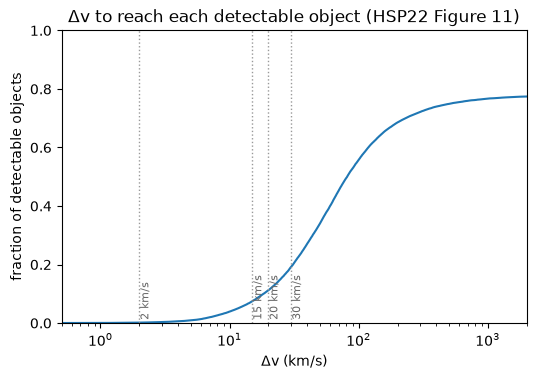

11% of detectable objects need Δv < 20 km/s (HSP22: about 20%)
12% if objects found after closest approach use the time since closest approach instead


In [11]:
fig, ax = plt.subplots(figsize=(6, 3.8))
x = np.sort(dv[detected])
ax.plot(x, np.arange(1, x.size + 1) / x.size)
for lim, lab in [(2, "2 km/s"), (15, "15 km/s"), (20, "20 km/s"), (30, "30 km/s")]:
    ax.axvline(lim, color="0.6", ls=":", lw=1)
    ax.text(lim, 0.02, lab, rotation=90, fontsize=8, color="0.4")
ax.set(xscale="log", xlim=(0.5, 2000), ylim=(0, 1), xlabel="Δv (km/s)", ylabel="fraction of detectable objects",
       title="Δv to reach each detectable object (HSP22 Figure 11)")
plt.show()
print(f"{np.mean(dv[detected] < 20):.0%} of detectable objects need Δv < 20 km/s (HSP22: about 20%)")
dv_abs = det["d_min"] / np.maximum(np.abs(wait), 1) * KMS
print(f"{np.mean(dv_abs[detected] < 20):.0%} if objects found after closest approach use the time since closest approach instead")

To turn fractions into rates, HSP22 assume a number density $n_0 = 0.1\ \mathrm{au}^{-3}$ of ʻOumuamua-like objects, so about 52 are inside the 5 au sphere at any moment. Each crosses it along a chord whose average length is $\tfrac{4}{3} \times 5$ au, at a typical speed of 20 km/s (conservative) or 40 km/s (optimistic). That gives about 33 or 66 new objects inside the sphere each year, which multiply the fractions:

In [12]:
r20, r40 = iso.rate_factor(20), iso.rate_factor(40)
print(f"Objects entering the 5 au sphere per year: {r20:.1f} (20 km/s) to {r40:.1f} (40 km/s)\n")

PAPER = {  # HSP22 Table 2: percentages
    22.4: (6.956, 2.828, 1.055, 0.424, 0.002), 23.4: (4.241, 1.457, 0.793, 0.347, 0.002),
    24.4: (1.933, 0.378, 0.284, 0.182, 0.002), 25.4: (0.739, 0.099, 0.091, 0.073, 0.001)}
labels = ["m ≤ 24", "detectable", "  and Δv < 30 km/s", "  and Δv < 15 km/s", "  and Δv < 2 km/s"]
for H in iso.H_LIST:
    dd = det[f"det_{H}"].astype(float)
    ok = dd >= 0
    w = det["t_ca"] - dd
    dvH = np.where(ok & (w > 0), det["d_min"] / np.where(w > 0, w, 1) * KMS, np.inf)
    counts = [np.sum(allq["m_min"] + (H - 22.4) <= 24), ok.sum(), np.sum(dvH < 30), np.sum(dvH < 15), np.sum(dvH < 2)]
    print(f"H = {H}:  {'':20s} {'this notebook':>14s} {'per year':>13s}   {'HSP22':>7s}")
    for lab, c, p in zip(labels, counts, PAPER[H]):
        f = c / N_OBJ
        print(f"   {lab:26s} {f:9.3%} {f'({c})':>8s}  {f * r20:5.2f}–{f * r40:<5.2f}  {p:6.3f}%")
    print()

Objects entering the 5 au sphere per year: 33.1 (20 km/s) to 66.3 (40 km/s)

H = 22.4:                        this notebook      per year     HSP22
   m ≤ 24                        6.274%  (62736)   2.08–4.16    6.956%
   detectable                    3.848%  (38477)   1.27–2.55    2.828%
     and Δv < 30 km/s            0.740%   (7401)   0.25–0.49    1.055%
     and Δv < 15 km/s            0.287%   (2875)   0.10–0.19    0.424%
     and Δv < 2 km/s             0.006%     (58)   0.00–0.00    0.002%

H = 23.4:                        this notebook      per year     HSP22
   m ≤ 24                        3.830%  (38296)   1.27–2.54    4.241%
   detectable                    1.930%  (19300)   0.64–1.28    1.457%
     and Δv < 30 km/s            0.312%   (3123)   0.10–0.21    0.793%
     and Δv < 15 km/s            0.107%   (1068)   0.04–0.07    0.347%
     and Δv < 2 km/s             0.002%     (21)   0.00–0.00    0.002%

H = 24.4:                        this notebook      per year     HSP2

For ʻOumuamua-like objects ($H = 22.4$) we find roughly 1.3–2.5 detections a year, so 13–25 over a 10-year survey, against HSP22's 0.9–1.9 a year (9–19 in all). The difference is the factor discussed in Section 4. Both are lower limits in one sense: fainter (smaller) objects drop out quickly as $H$ increases, but active comets like Borisov and 3I/ATLAS are far brighter than this model allows.

The $\Delta v$ fractions are of the same order as HSP22's, but ours are somewhat lower at 15–30 km/s: our whole-night test detects objects earlier, which on its own would lengthen the wait and lower $\Delta v$, but it also admits many objects first seen after their closest approach, which we count as unreachable. Reaching an object with $\Delta v < 2$ km/s, roughly the capability HSP22 attribute to ESA's *Comet Interceptor*, is very rare in both calculations: a few tens of objects in a million.

## 7. 1I, 2I and 3I in context

How typical were the three known visitors? We compare their speeds with the detectable population of ʻOumuamua-like objects.

In [13]:
v_det = allq["v_inf"][ids[detected]]
for name, (v, ra, dec) in KNOWN.items():
    sep = np.degrees(np.arccos(np.clip(
        np.sin(np.radians(dec)) * np.sin(np.radians(APEX[1])) +
        np.cos(np.radians(dec)) * np.cos(np.radians(APEX[1])) * np.cos(np.radians(ra - APEX[0])), -1, 1)))
    print(f"{name:14s} v_inf = {v:5.1f} km/s: faster than {np.mean(v_det < v):4.0%} of detectable objects; "
          f"radiant {sep:5.1f}° from the solar apex")

1I/ʻOumuamua   v_inf =  26.4 km/s: faster than  78% of detectable objects; radiant  15.4° from the solar apex
2I/Borisov     v_inf =  32.3 km/s: faster than  86% of detectable objects; radiant  86.3° from the solar apex
3I/ATLAS       v_inf =  58.0 km/s: faster than  99% of detectable objects; radiant  50.2° from the solar apex


ʻOumuamua arrived from close to the apex, as the model expects, but all three were faster than most of the model's detectable objects. The focusing weight strongly favours slow objects, so the median detectable object in this model has $v_\infty \approx 15$ km/s. 3I/ATLAS, at 58 km/s, is in the far tail of these G-dwarf kinematics, which suggests an older, kinematically hotter parent population. Three objects cannot test the model, but the LSST's sample should.

## 8. How much do the assumptions matter?

The numbers above rest on several choices: the stellar population whose kinematics the objects share, the solar motion, the gravitational-focusing weight, and the distribution of $b$. Here we rerun the whole Monte Carlo with one change at a time. The last row uses $p(b) \propto b$, what a uniform stream of objects passing through a disc would give, instead of HSP22's $p(b) \propto b^2$.

In [14]:
variants = [
    ("HSP22 choices (as above)", {}),
    ("Solar motion of Dehnen & Binney (1998)", dict(solar="Dehnen & Binney (1998)")),
    ("M-dwarf kinematics", dict(pop="M")),
    ("O/B-star kinematics", dict(pop="O/B")),
    ("No gravitational-focusing weight", dict(focus=False)),
    ("p(b) ∝ b instead of b²", dict(b_power=1)),
]
print(f"{'':42s} {'m ≤ 24':>8s} {'detectable':>11s} {'Δv < 15':>8s}  median v∞ of detectable")
with Pool(NPROC) as pool:
    for label, kw in variants:
        if not kw:
            aq, dt = allq, det
        else:
            aq, dt = iso.run(N_OBJ, N_CHUNK, pool, **kw)
        ok = dt["det_22.4"] >= 0
        w = dt["t_ca"] - dt["det_22.4"]
        dvv = np.where(ok & (w > 0), dt["d_min"] / np.where(w > 0, w, 1) * KMS, np.inf)
        print(f"{label:42s} {np.mean(aq['m_min'] <= 24):8.2%} {ok.sum() / N_OBJ:11.2%} {np.sum(dvv < 15) / N_OBJ:8.3%}"
              f"  {np.median(aq['v_inf'][dt['id'][ok]]):6.1f} km/s")

                                             m ≤ 24  detectable  Δv < 15  median v∞ of detectable


HSP22 choices (as above)                      6.27%       3.85%   0.287%    15.0 km/s


Solar motion of Dehnen & Binney (1998)        6.57%       4.01%   0.320%    14.2 km/s


M-dwarf kinematics                            5.67%       3.49%   0.244%    16.7 km/s


O/B-star kinematics                           7.77%       4.82%   0.345%    12.2 km/s


No gravitational-focusing weight              4.21%       2.63%   0.131%    27.1 km/s


p(b) ∝ b instead of b²                       15.06%       8.41%   0.637%    17.2 km/s


The kinematics and the solar motion change the detectable fraction by up to about a quarter. Without the focusing weight the population is faster; fast objects are bent less by the Sun's gravity, pass farther from it and spend less time nearby, so fewer of them become detectable. The distribution of $b$ matters most, because detection strongly favours small $b$: changing $b^2$ to $b$ roughly doubles the fraction. A full treatment would weight velocities by the flux through the sphere ($\propto v_\infty$) and derive the distribution of $b$ from it, but the absolute number density of interstellar objects, which scales every rate, is itself uncertain by at least a factor of two, and the LSST's real cadence and detection efficiency are not modelled here.

## Summary

* Following HSP22, we drew a million ʻOumuamua-like interstellar objects from the Schwarzschild velocity distribution of G dwarfs, shifted by the solar motion and weighted for gravitational focusing, and started them on the 5 au sphere.
* Their radiants cluster around the solar apex; detectable objects enter from the apex and anti-apex, but are first seen over a much wider area. We find only a weak concentration of the brightest objects towards the ecliptic, weaker than HSP22 report.
* About 6% of objects reach $m \le 24$ (HSP22: 7%). The detectable fraction depends on how night-time visibility is judged: 3.8% with a whole-night test, 1.1% at single instants, and 2.8% in HSP22.
* Detectable objects arrive on steep orbits, centred near 90° inclination, pass within about 1.5 au of the Earth, and are typically first seen weeks to months before closest approach.
* For a number density of 0.1 au⁻³, the LSST should find of order one to a few ʻOumuamua-like objects a year. Of these, around one in ten could be reached with $\Delta v < 20$ km/s; a target for a $\Delta v \approx 2$ km/s mission is very unlikely.
* The fractions are sensitive to the assumed kinematics, solar motion and especially the distribution of impact parameters, as well as to the objects' sizes and activity.

## Going further

* **Comets.** 2I and 3I were active, and far brighter than an inert body of the same size. Adding a heliocentric brightening law would raise the detection rates substantially (HSP22 suggest following Cook et al. 2016).
* **A survey cadence.** Replace the "whole sky south of +12°, every night" assumption with Rubin's real pointing history, from the LSST's simulated or actual observation logs.
* **Better intercepts.** The $\Delta v$ here is distance divided by time. Solving Lambert's problem for a transfer from Earth to each object would give a proper launch window.
* **Flux weighting.** Weight velocities by $v_\infty$ and draw $b$ from a uniform flux through a disc beyond the planets, then compare with Section 8.

## References

* Binney, J. & Merrifield, M. 1998, *Galactic Astronomy*, Princeton University Press. [ADS](https://ui.adsabs.harvard.edu/abs/1998gaas.book.....B/abstract)
* Chandler, C. O. et al. 2026, *NSF-DOE Vera C. Rubin Observatory Observations of Interstellar Comet 3I/ATLAS (C/2025 N1)*, ApJL 1001, L35. [ADS](https://ui.adsabs.harvard.edu/abs/2026ApJ..1001L..35C/abstract)
* Dehnen, W. & Binney, J. J. 1998, *Local stellar kinematics from HIPPARCOS data*, MNRAS 298, 387. [ADS](https://ui.adsabs.harvard.edu/abs/1998MNRAS.298..387D/abstract)
* ESA 1997, *The Hipparcos and Tycho Catalogues*, ESA SP-1200 (the ICRS-to-Galactic rotation matrix). [ADS](https://ui.adsabs.harvard.edu/abs/1997ESASP1200.....E/abstract)
* Guzik, P. et al. 2020, *Initial characterization of interstellar comet 2I/Borisov*, Nature Astronomy 4, 53. [ADS](https://ui.adsabs.harvard.edu/abs/2020NatAs...4...53G/abstract)
* Hoover, D. J., Seligman, D. Z. & Payne, M. J. 2022, *The Population of Interstellar Objects Detectable with the LSST and Accessible for In Situ Rendezvous with Various Mission Designs*, PSJ 3, 71. [ADS](https://ui.adsabs.harvard.edu/abs/2022PSJ.....3...71H/abstract)
* Ivezić, Ž. et al. 2019, *LSST: From Science Drivers to Reference Design and Anticipated Data Products*, ApJ 873, 111. [ADS](https://ui.adsabs.harvard.edu/abs/2019ApJ...873..111I/abstract)
* Mamajek, E. 2017, *Kinematics of the Interstellar Vagabond 1I/ʻOumuamua (A/2017 U1)*, RNAAS 1, 21. [ADS](https://ui.adsabs.harvard.edu/abs/2017RNAAS...1...21M/abstract)
* Meech, K. J. et al. 2017, *A brief visit from a red and extremely elongated interstellar asteroid*, Nature 552, 378. [ADS](https://ui.adsabs.harvard.edu/abs/2017Natur.552..378M/abstract)
* Rein, H. & Liu, S.-F. 2012, *REBOUND: an open-source multi-purpose N-body code for collisional dynamics*, A&A 537, A128. [ADS](https://ui.adsabs.harvard.edu/abs/2012A&A...537A.128R/abstract)
* Schönrich, R., Binney, J. & Dehnen, W. 2010, *Local kinematics and the local standard of rest*, MNRAS 403, 1829. [ADS](https://ui.adsabs.harvard.edu/abs/2010MNRAS.403.1829S/abstract)
* Seligman, D. & Laughlin, G. 2018, *The Feasibility and Benefits of In Situ Exploration of ʻOumuamua-like Objects*, AJ 155, 217. [ADS](https://ui.adsabs.harvard.edu/abs/2018AJ....155..217S/abstract)
* Seligman, D. Z. et al. 2025, *Discovery and Preliminary Characterization of a Third Interstellar Object: 3I/ATLAS*, ApJL 989, L36. [ADS](https://ui.adsabs.harvard.edu/abs/2025ApJ...989L..36S/abstract)

Orbital elements of 1I, 2I and 3I are from the JPL Small-Body Database (retrieved 2026-10-15). The Earth's position uses the low-precision solar coordinates of *The Astronomical Almanac*.